# 03 · Metrics & Efficiency Analysis

Publication figures and tables for the 5-phase study, built **only** from the consolidated files in
`<pipeline>/summary/` (written by `yolo26_seg/build_final_report.py`) plus the raw latency samples in
`phase5_test/efficiency/*.json`. No GPU is needed.

| Figure | Question it answers |
|---|---|
| 1 | Does accuracy (DSC, JSI) hold from cross-validation to the test set, and what does HPO add? |
| 2 | Is the HPO gain on the test set significant (paired, per image)? |
| 3 | How does accuracy scale with model size and compute? |
| 4 | Latency vs. FPS for FP32 and FP16 (network forward vs. full `predict()`). |
| 5 | How stable is the latency (median and P95)? |
| 6 | Memory footprint (VRAM, RAM). |
| 7 | Accuracy–latency trade-off for deployment. |
| A | Accuracy (DSC, JSI, Boundary IoU) vs. latency, FPS and parameters — standard in the three repositories. |
| B | Training time per phase and inference time (median, P95) with the real-time criterion — standard. |
| C | Boundary metrics (Boundary IoU, NSD, HD95) with 95 % CI — standard. |

Figures are saved as PDF (vector, for LaTeX) and PNG under `<pipeline>/figures/`; LaTeX tables under `<pipeline>/tables/`.
Colours follow a CVD-validated categorical palette; every chart also has a legend and a table view.

In [1]:
# ---- Configuration ----------------------------------------------------------
PIPELINE_NAME = "pipeline_final_v1"   # sub-directory of logs/ (or set $PIPELINE_DIR)
DEPLOY_VARIANT = "optimized"          # variant shown in the efficiency figures


import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Locate the repository and the pipeline outputs ------------------------
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()


def find_pipeline_dir(name: str) -> Path | None:
    """$PIPELINE_DIR, else the Docker mount, else <repo>/logs/<name>; None if none exists yet."""
    candidates = [os.environ.get("PIPELINE_DIR"), f"/workspace/logs/{name}", REPO_ROOT / "logs" / name]
    for c in candidates:
        if c and Path(c).is_dir():
            return Path(c)
    print(f"[info] pipeline outputs not found; tried {candidates}. Set PIPELINE_DIR.")
    return None


#: Where the YOLO26 dataset (images + labels, the source of truth) may live on the host.
YOLO_DATASET_CANDIDATES = [REPO_ROOT / "datasets" / "isic2018_task1_official",
                           REPO_ROOT.parent / "sandbox_yolo26" / "datasets" / "isic2018_task1_official",
                           # earlier export (results produced before the official-release rebuild)
                           REPO_ROOT / "datasets" / "isic_2018_task1_yolo26",
                           REPO_ROOT.parent / "sandbox_yolo26" / "datasets" / "isic_2018_task1_yolo26"]


def local_path(p) -> Path:
    """Map /workspace/... paths recorded inside Docker to this machine when run on the host."""
    p = Path(p)
    if p.exists():
        return p
    s = str(p)
    for prefix in ("/workspace/yolo26_dataset/", "/workspace/datasets/isic2018_task1_official/",
                   "/workspace/datasets/isic_2018_task1_yolo26/"):
        if s.startswith(prefix):
            for root in YOLO_DATASET_CANDIDATES:
                if (root / s[len(prefix):]).exists():
                    return root / s[len(prefix):]
    if s.startswith("/workspace/") and (REPO_ROOT / p.relative_to("/workspace")).exists():
        return REPO_ROOT / p.relative_to("/workspace")
    return p


PHASE5_MISSING = "⚠️ Phase 5 results not yet generated. Training is likely still in progress. Skipping cell execution."
PHASE5_READY = False   # set by the data-loading cell; every later cell is skipped while it is False
PIPELINE_DIR = find_pipeline_dir(PIPELINE_NAME) or REPO_ROOT / "logs" / PIPELINE_NAME
FIG_DIR = PIPELINE_DIR / "figures"

# ---- Figure style (publication, light) -------------------------------------
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": INK_2, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2, "lines.markersize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


def save(fig, name: str) -> None:
    """Save a figure as vector PDF (for LaTeX) and 300-dpi PNG under <pipeline>/figures/."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight", dpi=300)
    print(f"saved {FIG_DIR / name}.pdf|png")


print("pipeline :", PIPELINE_DIR)
print("figures  :", FIG_DIR)


MODELS = ["nano", "small", "medium", "large", "xlarge"]
SHORT = {"nano": "n", "small": "s", "medium": "m", "large": "l", "xlarge": "x"}
# Categorical colours: validated light-mode slots (all-pairs CVD ΔE ≥ 9). Colour follows the entity.
SERIES = {"cv": "#2a78d6", "baseline": "#eb6834", "optimized": "#1baf7a"}
SERIES_LABEL = {"cv": "Phase 2 · 5-fold CV (held-out folds)",
                "baseline": "Phase 5 · Test — Baseline", "optimized": "Phase 5 · Test — Optimized"}
PREC = {"fp32": "#2a78d6", "fp16": "#4a3aa7"}
MARKER = {"baseline": "s", "optimized": "o", "fp32": "o", "fp16": "^"}
TABLE_DIR = PIPELINE_DIR / "tables"

pipeline : /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1
figures  : /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures


In [2]:
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter


def log_axis(ax, axis: str = "x") -> None:
    """Log scale with plain-number ticks (1-2-5, 1-3 or decades, by the span of the data); call after plotting."""
    (ax.set_xscale if axis == "x" else ax.set_yscale)("log")
    a = ax.xaxis if axis == "x" else ax.yaxis
    lo, hi = ax.get_xlim() if axis == "x" else ax.get_ylim()
    span = np.log10(hi / lo) if lo > 0 and hi > lo else 1.0
    a.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0) if span <= 1.6 else (1.0, 3.0) if span <= 2.6 else (1.0,)))
    a.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}"))
    a.set_minor_formatter(NullFormatter())


SUMMARY = PIPELINE_DIR / "summary"


def read_csv(name: str) -> pd.DataFrame:
    p = SUMMARY / f"{name}.csv"
    if not p.exists():
        print(f"[missing] {p} — run build_final_report.py")
        return pd.DataFrame()
    return pd.read_csv(p)


acc, eff, gain, cv_pix, cv_inst = (read_csv(n) for n in
                                   ("test_accuracy", "efficiency", "hpo_gain", "phase2_cv_pixel", "phase2_cv_baseline"))
report = json.loads((SUMMARY / "final_results.json").read_text()) if (SUMMARY / "final_results.json").exists() else {}

present = set(acc["model"]) if len(acc) else set()
MODELS = [m for m in MODELS if m in present] or MODELS
X = np.arange(len(MODELS))
acc32 = acc[acc.precision == "fp32"] if len(acc) else acc

print(f"models: {MODELS}")
for w in report.get("warnings", []):
    print("WARNING:", w)

PHASE5_READY = not acc.empty and not eff.empty
if not PHASE5_READY:
    print(PHASE5_MISSING)

models: ['nano', 'small', 'medium', 'large', 'xlarge']


## Figure 1 — DSC and JSI across phases

Per model: Phase 2 cross-validation (mean ± sample SD over the 5 held-out folds; Baseline protocol), and the test set
for the Baseline and the Optimized models (per-image mean with seeded bootstrap 95 % CI). A dot plot is used because
the values are close together; bars would have to start at zero and hide the differences.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/fig1_dsc_jsi_across_phases.pdf|png


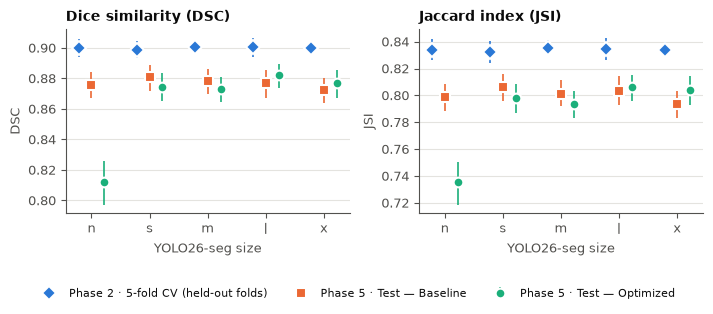

,model,cv_dsc_mean,cv_dsc_std,cv_jsi_mean,cv_jsi_std,test_baseline_dsc_mean,test_baseline_dsc_ci95_low,test_baseline_dsc_ci95_high,test_baseline_jsi_mean,test_optimized_dsc_mean,test_optimized_dsc_ci95_low,test_optimized_dsc_ci95_high,test_optimized_jsi_mean
0,nano,0.9001,0.0060,0.8341,0.0075,0.8758,0.8669,0.8840,0.7987,0.8121,0.7972,0.8261,0.7352
1,small,0.8989,0.0055,0.8326,0.0081,0.8809,0.8719,0.8889,0.8064,0.8747,0.8653,0.8833,0.7978
2,medium,0.9009,0.0042,0.8354,0.0055,0.8780,0.8700,0.8860,0.8013,0.8728,0.8642,0.8809,0.7937
3,large,0.9003,0.0065,0.8348,0.0082,0.8767,0.8670,0.8856,0.8035,0.8819,0.8739,0.8897,0.8059
4,xlarge,0.8998,0.0044,0.8342,0.0057,0.8722,0.8636,0.8804,0.7934,0.8771,0.8673,0.8856,0.8042


In [3]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    def series_stats(key: str, metric: str):
        """(mean, 2×N error) — CV: ± sample SD over folds; test: bootstrap 95 % CI."""
        if key == "cv":
            d = cv_pix.set_index("model").reindex(MODELS)
            return d[f"{metric}_mean"].to_numpy(), np.vstack([d[f"{metric}_std"].to_numpy()] * 2)
        d = acc32[acc32.variant == key].set_index("model").reindex(MODELS)
        m = d[f"{metric}_mean"].to_numpy()
        return m, np.vstack([m - d[f"{metric}_ci95_low"].to_numpy(), d[f"{metric}_ci95_high"].to_numpy() - m])


    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9))
    offsets = {"cv": -0.22, "baseline": 0.0, "optimized": 0.22}
    for ax, metric, title in zip(axes, ("dsc", "jsi"), ("Dice similarity (DSC)", "Jaccard index (JSI)")):
        for key in ("cv", "baseline", "optimized"):
            if key == "cv" and cv_pix.empty:
                continue
            mean, err = series_stats(key, metric)
            ax.errorbar(X + offsets[key], mean, yerr=err, fmt=MARKER.get(key, "D"),
                        color=SERIES[key], ecolor=SERIES[key], elinewidth=1.2, capsize=0,
                        markeredgecolor=SURFACE, markeredgewidth=1.5, markersize=7, label=SERIES_LABEL[key])
        ax.set_xticks(X, [SHORT[m] for m in MODELS])
        ax.set_xlabel("YOLO26-seg size")
        ax.set_title(title)
        ax.set_ylabel(metric.upper())
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08))
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    save(fig, "fig1_dsc_jsi_across_phases")
    plt.show()

    table1 = pd.DataFrame({"model": MODELS})
    if not cv_pix.empty:
        table1 = table1.merge(cv_pix[["model", "dsc_mean", "dsc_std", "jsi_mean", "jsi_std"]]
                              .rename(columns=lambda c: c if c == "model" else f"cv_{c}"), on="model", how="left")
    for v in ("baseline", "optimized"):
        d = acc32[acc32.variant == v][["model", "dsc_mean", "dsc_ci95_low", "dsc_ci95_high", "jsi_mean"]]
        table1 = table1.merge(d.rename(columns=lambda c: c if c == "model" else f"test_{v}_{c}"), on="model", how="left")
    display(table1.round(4))

## Figure 2 — HPO gain on the test set (paired)

Optimized − Baseline per image on the same test images: mean difference with paired bootstrap 95 % CI.
The label is the two-sided Wilcoxon signed-rank *p*-value. An interval that crosses zero means no reliable gain.

saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/fig2_hpo_gain.pdf|png


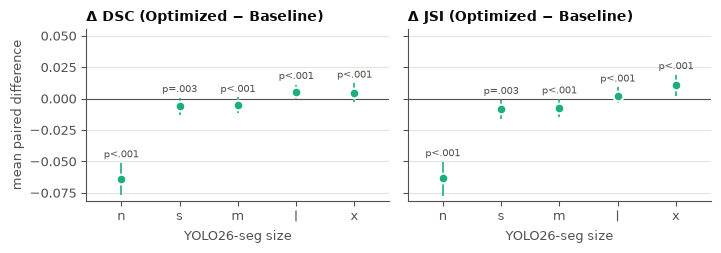

,n_images,dsc_baseline,dsc_optimized,delta_dsc,delta_dsc_ci95_low,delta_dsc_ci95_high,wilcoxon_p_dsc,n_improved_dsc,n_worse_dsc,delta_jsi,wilcoxon_p_jsi,delta_map5095_m
model,,,,,,,,,,,,
nano,1000,0.8758,0.8121,-0.0637,-0.0768,-0.0511,0.0000,497,502,-0.0635,0.0000,0.0185
small,1000,0.8809,0.8747,-0.0062,-0.0130,0.0008,0.0032,472,527,-0.0086,0.0026,-0.0337
medium,1000,0.8780,0.8728,-0.0052,-0.0117,0.0009,0.0002,431,567,-0.0076,0.0002,-0.0182
large,1000,0.8767,0.8819,0.0052,-0.0001,0.0112,0.0004,435,564,0.0024,0.0003,-0.0139
xlarge,1000,0.8722,0.8771,0.0049,-0.0026,0.0123,0.0000,582,417,0.0108,0.0000,0.0151


In [4]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    def fmt_p(p: float) -> str:
        """APA-style p-value label."""
        if not np.isfinite(p):
            return "p = n/a"
        return "p<.001" if p < 0.001 else f"p={p:.3f}".replace("0.", ".")


    if gain.empty:
        print("hpo_gain.csv missing — run Phase 5")
    else:
        g = gain.set_index("model").reindex(MODELS)
        fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), sharey=True)
        for ax, k, title in zip(axes, ("dsc", "jsi"), ("Δ DSC (Optimized − Baseline)", "Δ JSI (Optimized − Baseline)")):
            d = g[f"delta_{k}"].to_numpy()
            err = np.vstack([d - g[f"delta_{k}_ci95_low"].to_numpy(), g[f"delta_{k}_ci95_high"].to_numpy() - d])
            ax.axhline(0, color=INK_2, linewidth=0.8)
            ax.errorbar(X, d, yerr=err, fmt="o", color=SERIES["optimized"], elinewidth=1.2, capsize=0,
                        markeredgecolor=SURFACE, markeredgewidth=1.5, markersize=7)
            for xi, di, hi, p in zip(X, d, g[f"delta_{k}_ci95_high"], g[f"wilcoxon_p_{k}"]):
                ax.annotate(fmt_p(p), (xi, hi), xytext=(0, 4), textcoords="offset points",
                            ha="center", fontsize=7, color=INK_2)
            lo, hi_ = ax.get_ylim()
            ax.set_ylim(min(lo, 0), hi_ + 0.18 * (hi_ - min(lo, 0)))  # headroom for the p labels
            ax.set_xlim(-0.6, len(MODELS) - 0.4)
            ax.set_xticks(X, [SHORT[m] for m in MODELS])
            ax.set_xlabel("YOLO26-seg size")
            ax.set_title(title)
        axes[0].set_ylabel("mean paired difference")
        fig.tight_layout()
        save(fig, "fig2_hpo_gain")
        plt.show()
        display(gain.set_index("model").reindex(MODELS)[
            ["n_images", "dsc_baseline", "dsc_optimized", "delta_dsc", "delta_dsc_ci95_low", "delta_dsc_ci95_high",
             "wilcoxon_p_dsc", "n_improved_dsc", "n_worse_dsc", "delta_jsi", "wilcoxon_p_jsi", "delta_map5095_m"]].round(4))

## Figure 3 — Accuracy vs. model size and compute

Test-set mask mAP@50-95 and DSC against the FP32 weight size (fused parameters × 4 bytes) and GFLOPs at 640×640.
Lines connect the sizes of each variant in order (n → x). The x-axes are logarithmic.

saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/fig3_accuracy_vs_size.pdf|png


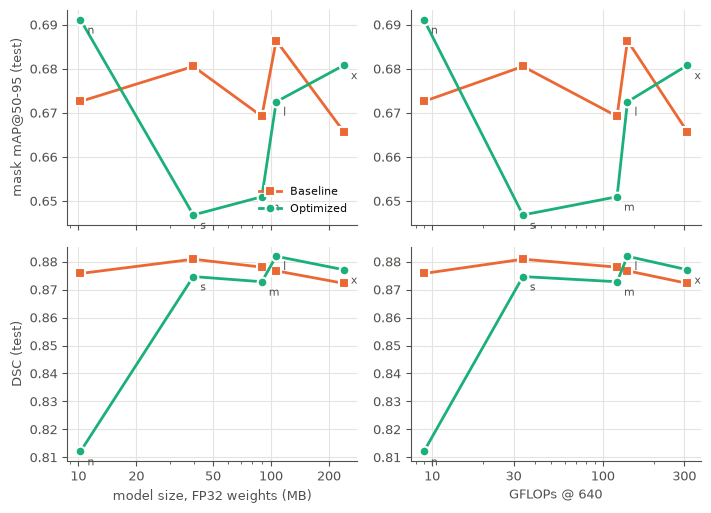

,baseline · map5095_m,optimized · map5095_m,baseline · dsc_mean,optimized · dsc_mean,size_mb_fp32_theoretical,size_mb_disk,gflops,params_fused
model,,,,,,,,
nano,0.6726,0.6911,0.8758,0.8121,10.2580,6.2555,8.9572,2689079
small,0.6805,0.6468,0.8809,0.8747,39.5421,22.2774,34.0465,10365727
medium,0.6692,0.6510,0.8780,0.8728,89.6768,51.9697,121.1593,23508239
large,0.6864,0.6725,0.8767,0.8819,106.4473,60.5086,139.4066,27904527
xlarge,0.6657,0.6808,0.8722,0.8771,239.2879,135.1739,312.9829,62727887


In [5]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    cost = (eff[(eff.variant == DEPLOY_VARIANT) & (eff.precision == "fp32")]
            .set_index("model")[["size_mb_fp32_theoretical", "size_mb_disk", "gflops", "params_fused"]])
    fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.2), sharex="col")
    for row, (metric, ylab) in enumerate((("map5095_m", "mask mAP@50-95 (test)"), ("dsc_mean", "DSC (test)"))):
        for col, (cx, xlab) in enumerate((("size_mb_fp32_theoretical", "model size, FP32 weights (MB)"), ("gflops", "GFLOPs @ 640"))):
            ax = axes[row, col]
            for v in ("baseline", "optimized"):
                d = acc32[acc32.variant == v].set_index("model").reindex(MODELS).join(cost)
                ax.plot(d[cx], d[metric], color=SERIES[v], marker=MARKER[v], markeredgecolor=SURFACE,
                        markeredgewidth=1.5, label=SERIES_LABEL[v].split("— ")[1])
                if v == "optimized":
                    for m, xv, yv in zip(MODELS, d[cx], d[metric]):
                        ax.annotate(SHORT[m], (xv, yv), xytext=(5, -10), textcoords="offset points", fontsize=8, color=INK_2)
            log_axis(ax, "x")
            ax.grid(True, axis="both")
            if row == 1:
                ax.set_xlabel(xlab)
            if col == 0:
                ax.set_ylabel(ylab)
    axes[0, 0].legend(loc="lower right")
    fig.tight_layout()
    save(fig, "fig3_accuracy_vs_size")
    plt.show()
    t3 = acc32.pivot(index="model", columns="variant", values=["map5095_m", "dsc_mean"]).reindex(MODELS)
    t3.columns = [f"{v} · {k}" for k, v in t3.columns]
    display(t3.join(cost).round(4))

## Figure 4 — Latency vs. FPS (batch = 1)

Each point is one model at one precision. Filled markers: network forward pass (timed with `torch.cuda.Event`);
hollow markers: full `predict()` (pre-processing + inference + mask post-processing). FPS = 1000 / mean latency,
so points lie near the grey reference curve; what matters is how far along it each model sits and the
forward → end-to-end gap. Baseline and Optimized share the architecture, so only the deployed variant is shown.

saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/fig4_latency_vs_fps.pdf|png


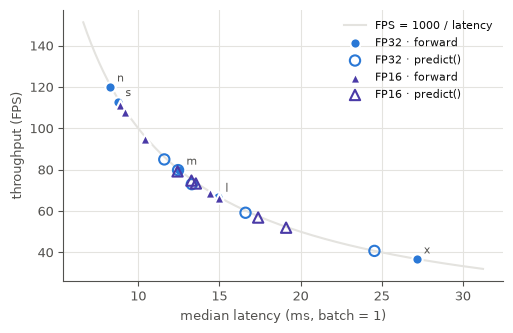

fwd_median_ms  fwd_p95_ms  fwd_p99_ms  fwd_fps  \
model  precision                                                   
nano   fp32                8.26        8.85        9.89   119.98   
       fp16                8.89        9.67       10.86   111.09   
small  fp32                8.78        9.18       10.49   112.92   
       fp16                9.18        9.68       11.17   107.95   
medium fp32               12.54       12.68       12.87    79.75   
       fp16               10.41       11.22       12.49    95.05   
large  fp32               14.94       15.47       17.10    66.61   
       fp16               14.41       15.42       17.34    68.56   
xlarge fp32               27.17       27.41       27.64    36.79   
       fp16               14.97       15.64       17.74    66.19   

                  e2e_median_ms  e2e_p95_ms  e2e_fps  e2e_dataset_median_ms  \
model  precision                                                              
nano   fp32               12.45       12.82    79.79                  11.56   
       fp16               13.55       14.06    73.33                  12.32   
small  fp32               11.60       12.72    84.97                  11.69   
       fp16               12.42       14.11    79.17                  12.50   
medium fp32               13.30       15.43    72.99                  13.46   
       fp16               13.28       13.85    74.72                  13.51   
large  fp32               16.61       18.50    59.17                  16.66   
       fp16               17.39       18.27    56.84                  17.67   
xlarge fp32               24.55       24.83    40.71                  23.25   
       fp16               19.11       19.84    51.94                  17.96   

                  e2e_dataset_p95_ms  contended  
model  precision                                 
nano   fp32                    12.69      False  
       fp16                    13.59      False  
small  fp32                    12.40      False  
       fp16                    14.29      False  
medium fp32                    14.13      False  
       fp16                    15.67      False  
large  fp32                    18.91      False  
       fp16                    19.20      False  
xlarge fp32                    24.59      False  
       fp16                    19.67      False

In [6]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    e = eff[eff.variant == DEPLOY_VARIANT]
    fig, ax = plt.subplots(figsize=(5.2, 3.4))
    lat = np.linspace(max(0.5, e[["fwd_median_ms", "e2e_median_ms"]].min().min() * 0.8),
                      e[["fwd_median_ms", "e2e_median_ms"]].max().max() * 1.15, 200)
    ax.plot(lat, 1000 / lat, color=GRID, linewidth=1.5, zorder=0, label="FPS = 1000 / latency")
    for prec in ("fp32", "fp16"):
        d = e[e.precision == prec].set_index("model").reindex(MODELS)
        ax.scatter(d.fwd_median_ms, d.fwd_fps, color=PREC[prec], marker=MARKER[prec], s=55,
                   edgecolor=SURFACE, linewidth=1.5, label=f"{prec.upper()} · forward", zorder=3)
        ax.scatter(d.e2e_median_ms, d.e2e_fps, facecolor="none", edgecolor=PREC[prec], marker=MARKER[prec],
                   s=55, linewidth=1.5, label=f"{prec.upper()} · predict()", zorder=3)
        if prec == "fp32":
            for m, xv, yv in zip(MODELS, d.fwd_median_ms, d.fwd_fps):
                ax.annotate(SHORT[m], (xv, yv), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK_2)
    ax.set_xlabel("median latency (ms, batch = 1)")
    ax.set_ylabel("throughput (FPS)")
    ax.grid(True, axis="both")
    ax.legend(ncol=1, loc="upper right")
    fig.tight_layout()
    save(fig, "fig4_latency_vs_fps")
    plt.show()
    display(e.set_index(["model", "precision"])[
        [c for c in ("fwd_median_ms", "fwd_p95_ms", "fwd_p99_ms", "fwd_fps", "e2e_median_ms", "e2e_p95_ms", "e2e_fps",
                     "e2e_dataset_median_ms", "e2e_dataset_p95_ms", "contended") if c in e]
    ].reindex(MODELS, level=0).round(2))

## Figure 5 — Latency distribution (median and P95)

Box = interquartile range, centre line = median, whiskers = P5–P95 of the timed forward passes
(warm-up excluded). A short upper whisker means a stable, predictable latency.

saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/fig5_latency_distribution.pdf|png


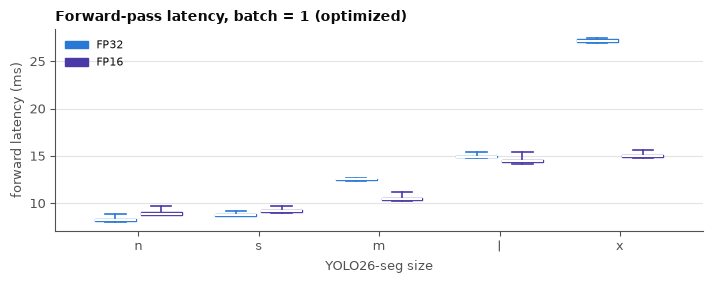

,median,P95,P99,P95 − median
nano/fp32,8.262,8.852,9.891,0.590
nano/fp16,8.894,9.669,10.863,0.775
small/fp32,8.779,9.182,10.491,0.403
small/fp16,9.182,9.682,11.166,0.500
medium/fp32,12.537,12.682,12.875,0.145
medium/fp16,10.414,11.220,12.490,0.806
large/fp32,14.938,15.470,17.097,0.532
large/fp16,14.411,15.416,17.338,1.005
xlarge/fp32,27.169,27.413,27.640,0.244
xlarge/fp16,14.974,15.640,17.745,0.666


In [7]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    raw = {}
    for m in MODELS:
        for prec in ("fp32", "fp16"):
            p = PIPELINE_DIR / "phase5_test" / "efficiency" / f"{DEPLOY_VARIANT}_{m}_{prec}.json"
            if p.exists():
                raw[(m, prec)] = json.loads(p.read_text())["forward"]["raw_ms"]

    fig, ax = plt.subplots(figsize=(7.2, 2.9))
    width = 0.34
    for i, prec in enumerate(("fp32", "fp16")):
        data = [raw.get((m, prec), [np.nan]) for m in MODELS]
        pos = X + (i - 0.5) * (width + 0.04)
        bp = ax.boxplot(data, positions=pos, widths=width, whis=(5, 95), showfliers=False, patch_artist=True,
                        medianprops=dict(color=SURFACE, linewidth=1.5),
                        boxprops=dict(facecolor=PREC[prec], edgecolor=PREC[prec]),
                        whiskerprops=dict(color=PREC[prec], linewidth=1.2), capprops=dict(color=PREC[prec], linewidth=1.2))
        bp["boxes"][0].set_label(prec.upper())
    ax.set_xticks(X, [SHORT[m] for m in MODELS])
    ax.set_xlabel("YOLO26-seg size")
    ax.set_ylabel("forward latency (ms)")
    ax.set_title(f"Forward-pass latency, batch = 1 ({DEPLOY_VARIANT})")
    ax.legend(loc="upper left")
    fig.tight_layout()
    save(fig, "fig5_latency_distribution")
    plt.show()
    display(pd.DataFrame({f"{m}/{p}": {"median": np.median(v), "P95": np.percentile(v, 95), "P99": np.percentile(v, 99),
                               "P95 − median": np.percentile(v, 95) - np.median(v)} for (m, p), v in raw.items()}).T.round(3))

## Figure 6 — Memory footprint

Peak GPU memory of batch-1 inference, measured two ways, and the peak host RAM of the benchmark process:
**allocator** = steady-state peak allocated by PyTorch (forward pass / full prediction pipeline; cuDNN autotuning
workspaces of the warm-up and the CUDA context excluded) — the model's own footprint; **process** = device memory
held by the benchmark process as reported by the driver (`nvidia-smi`), CUDA context, kernels and allocator cache
included — what a deployment GPU must actually provide.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/fig6_memory.pdf|png


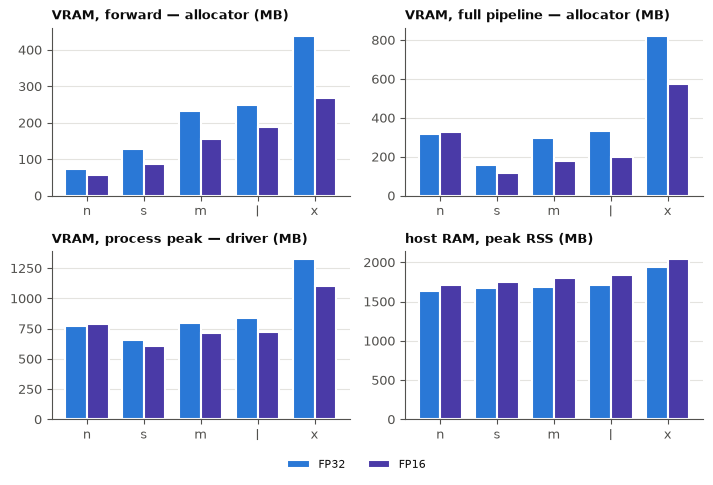

vram_weights_mb  vram_peak_allocated_mb  \
model  precision                                            
nano   fp32                  10.4                    73.7   
       fp16                   5.2                    56.0   
small  fp32                  39.7                   129.1   
       fp16                  19.9                    86.5   
medium fp32                  89.8                   232.4   
       fp16                  44.9                   155.2   
large  fp32                 106.6                   249.2   
       fp16                  53.3                   188.6   
xlarge fp32                 239.4                   439.0   
       fp16                 119.7                   268.6   

                  vram_peak_allocated_e2e_mb  vram_cuda_context_mb  \
model  precision                                                     
nano   fp32                            318.2                 370.0   
       fp16                            328.2                 370.0   
small  fp32                            159.7                 370.0   
       fp16                            118.9                 370.0   
medium fp32                            297.1                 370.0   
       fp16                            180.8                 370.0   
large  fp32                            330.0                 370.0   
       fp16                            197.6                 370.0   
xlarge fp32                            822.7                 370.0   
       fp16                            573.8                 370.0   

                  vram_process_peak_mb  ram_peak_rss_mb  size_mb_disk  \
model  precision                                                        
nano   fp32                      774.0           1635.6           6.3   
       fp16                      790.0           1712.0           6.3   
small  fp32                      658.0           1671.2          22.3   
       fp16                      610.0           1745.5          22.3   
medium fp32                      794.0           1681.3          52.0   
       fp16                      710.0           1804.2          52.0   
large  fp32                      842.0           1711.4          60.5   
       fp16                      726.0           1842.5          60.5   
xlarge fp32                     1324.0           1936.0         135.2   
       fp16                     1104.0           2039.0         135.2   

                  size_mb_fp32_theoretical  size_mb_fp16_theoretical  \
model  precision                                                       
nano   fp32                           10.3                       5.1   
       fp16                           10.3                       5.1   
small  fp32                           39.5                      19.8   
       fp16                           39.5                      19.8   
medium fp32                           89.7                      44.8   
       fp16                           89.7                      44.8   
large  fp32                          106.4                      53.2   
       fp16                          106.4                      53.2   
xlarge fp32                          239.3                     119.6   
       fp16                          239.3                     119.6   

                  params_fused  gflops  
model  precision                        
nano   fp32            2689079     9.0  
       fp16            2689079     9.0  
small  fp32           10365727    34.0  
       fp16           10365727    34.0  
medium fp32           23508239   121.2  
       fp16           23508239   121.2  
large  fp32           27904527   139.4  
       fp16           27904527   139.4  
xlarge fp32           62727887   313.0  
       fp16           62727887   313.0

In [8]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.8))
    panels = (("vram_peak_allocated_mb", "VRAM, forward — allocator (MB)"),
              ("vram_peak_allocated_e2e_mb", "VRAM, full pipeline — allocator (MB)"),
              ("vram_process_peak_mb", "VRAM, process peak — driver (MB)"),
              ("ram_peak_rss_mb", "host RAM, peak RSS (MB)"))
    w = 0.38
    for ax, (col, title) in zip(axes.flat, panels):
        for i, prec in enumerate(("fp32", "fp16")):
            d = e[e.precision == prec].set_index("model").reindex(MODELS)
            v = d[col] if col in d else pd.Series(np.nan, index=d.index)
            ax.bar(X + (i - 0.5) * w, v, width=w, color=PREC[prec], edgecolor=SURFACE, linewidth=1.5, label=prec.upper())
        ax.set_xticks(X, [SHORT[m] for m in MODELS])
        ax.set_title(title, fontsize=9)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    save(fig, "fig6_memory")
    plt.show()
    display(e.set_index(["model", "precision"])[
        [c for c in ("vram_weights_mb", "vram_peak_allocated_mb", "vram_peak_allocated_e2e_mb", "vram_cuda_context_mb",
                     "vram_process_peak_mb", "ram_peak_rss_mb", "size_mb_disk", "size_mb_fp32_theoretical",
                     "size_mb_fp16_theoretical", "params_fused", "gflops") if c in e]
    ].reindex(MODELS, level=0).round(1))

## Figure 7 — Accuracy–latency trade-off

Test DSC of the deployed variant against its end-to-end median latency, in FP32 and FP16
(FP16 accuracy is measured, not assumed). Models up and to the left dominate.

saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/fig7_accuracy_latency_tradeoff.pdf|png


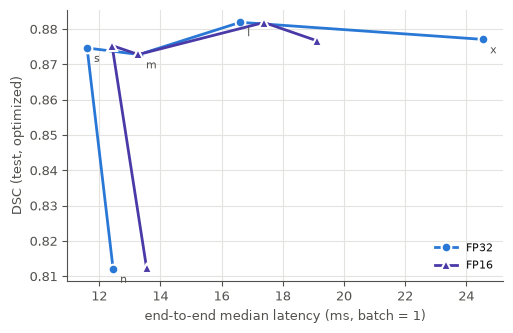

In [9]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    fig, ax = plt.subplots(figsize=(5.2, 3.4))
    for prec in ("fp32", "fp16"):
        a = acc[(acc.variant == DEPLOY_VARIANT) & (acc.precision == prec)].set_index("model").reindex(MODELS)
        l = e[e.precision == prec].set_index("model").reindex(MODELS)
        ax.plot(l.e2e_median_ms, a.dsc_mean, color=PREC[prec], marker=MARKER[prec], markeredgecolor=SURFACE,
                markeredgewidth=1.5, label=prec.upper())
        if prec == "fp32":
            for m, xv, yv in zip(MODELS, l.e2e_median_ms, a.dsc_mean):
                ax.annotate(SHORT[m], (xv, yv), xytext=(5, -10), textcoords="offset points", fontsize=8, color=INK_2)
    ax.set_xlabel("end-to-end median latency (ms, batch = 1)")
    ax.set_ylabel(f"DSC (test, {DEPLOY_VARIANT})")
    ax.grid(True, axis="both")
    ax.legend()
    fig.tight_layout()
    save(fig, "fig7_accuracy_latency_tradeoff")
    plt.show()

<!-- standard-committee-figures -->
## Standard figure A — Accuracy vs. efficiency (deployed variant, batch = 1)

Test-set accuracy — overlap (DSC, JSI) and contour adherence (Boundary IoU) — against the three deployment costs the
committee asked for: median forward latency, throughput (FPS) and parameter count. Each point is one model at one
precision (FP32 circles, FP16 triangles) with its seeded bootstrap 95 % CI; x-axes are logarithmic. Identical cell
in the YOLO26, U-Net and SAM 3 notebooks; the root notebook `04_cross_architecture_results.ipynb` draws the same plot
across architectures.

saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/figA_accuracy_vs_efficiency.pdf|png


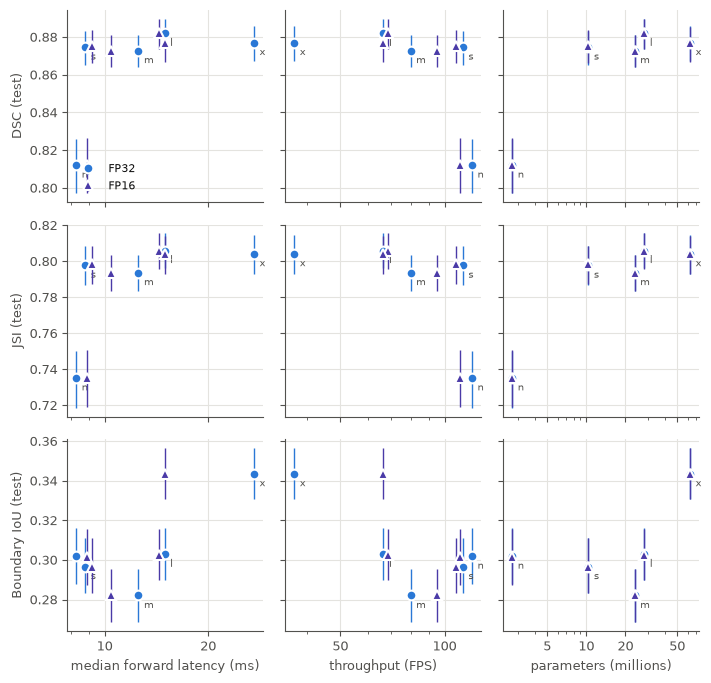

dsc_mean  dsc_ci95_low  dsc_ci95_high  jsi_mean  \
model  precision                                                    
nano   fp32         0.8121        0.7972         0.8261    0.7352   
       fp16         0.8123        0.7972         0.8263    0.7354   
small  fp32         0.8747        0.8653         0.8833    0.7978   
       fp16         0.8753        0.8661         0.8839    0.7984   
medium fp32         0.8728        0.8642         0.8809    0.7937   
       fp16         0.8728        0.8642         0.8809    0.7937   
large  fp32         0.8819        0.8739         0.8897    0.8059   
       fp16         0.8819        0.8738         0.8896    0.8059   
xlarge fp32         0.8771        0.8673         0.8856    0.8042   
       fp16         0.8767        0.8669         0.8853    0.8040   

                  jsi_ci95_low  jsi_ci95_high  biou_mean  biou_ci95_low  \
model  precision                                                          
nano   fp32             0.7185         0.7504     0.3019         0.2878   
       fp16             0.7188         0.7505     0.3017         0.2876   
small  fp32             0.7868         0.8082     0.2966         0.2832   
       fp16             0.7875         0.8086     0.2967         0.2832   
medium fp32             0.7833         0.8036     0.2821         0.2684   
       fp16             0.7833         0.8036     0.2822         0.2685   
large  fp32             0.7960         0.8155     0.3028         0.2901   
       fp16             0.7959         0.8154     0.3026         0.2898   
xlarge fp32             0.7929         0.8145     0.3436         0.3307   
       fp16             0.7928         0.8142     0.3436         0.3307   

                  biou_ci95_high  fwd_median_ms   fwd_fps  params_M  
model  precision                                                     
nano   fp32               0.3160         8.2616  119.9835    2.6891  
       fp16               0.3157         8.8939  111.0933    2.6891  
small  fp32               0.3110         8.7792  112.9198   10.3657  
       fp16               0.3110         9.1817  107.9548   10.3657  
medium fp32               0.2954        12.5368   79.7501   23.5082  
       fp16               0.2955        10.4141   95.0458   23.5082  
large  fp32               0.3161        14.9381   66.6140   27.9045  
       fp16               0.3158        14.4113   68.5631   27.9045  
xlarge fp32               0.3564        27.1688   36.7853   62.7279  
       fp16               0.3566        14.9740   66.1863   62.7279

In [10]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    d_acc = acc[acc.variant == DEPLOY_VARIANT]
    d_eff = eff[eff.variant == DEPLOY_VARIANT]
    both = d_acc.merge(d_eff, on=["variant", "model", "precision"], suffixes=("", "_eff")).copy()   # de-fragment
    both["params_M"] = both["params_fused"] / 1e6
    y_rows = [("dsc", "DSC (test)"), ("jsi", "JSI (test)")]
    if "biou_mean" in both and both["biou_mean"].notna().any():
        y_rows.append(("biou", "Boundary IoU (test)"))
    x_cols = [("fwd_median_ms", "median forward latency (ms)"), ("fwd_fps", "throughput (FPS)"),
              ("params_M", "parameters (millions)")]
    fig, axes = plt.subplots(len(y_rows), len(x_cols), figsize=(7.2, 2.3 * len(y_rows)), squeeze=False,
                             sharex="col", sharey="row")
    for r, (yk, ylab) in enumerate(y_rows):
        for c, (xc, xlab) in enumerate(x_cols):
            ax = axes[r, c]
            for prec in ("fp32", "fp16"):
                d = both[both.precision == prec].set_index("model").reindex(MODELS)
                y = d[f"{yk}_mean"].to_numpy()
                yerr = np.vstack([y - d[f"{yk}_ci95_low"].to_numpy(), d[f"{yk}_ci95_high"].to_numpy() - y])
                ax.errorbar(d[xc], y, yerr=yerr, fmt=MARKER[prec], color=PREC[prec], elinewidth=1, capsize=0,
                            markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label=prec.upper(), zorder=3)
                if prec == "fp32":
                    for m, xv, yv in zip(MODELS, d[xc], y):
                        ax.annotate(SHORT[m], (xv, yv), xytext=(4, -9), textcoords="offset points", fontsize=7, color=INK_2)
            log_axis(ax, "x")
            ax.grid(True, axis="both")
            if r == len(y_rows) - 1:
                ax.set_xlabel(xlab)
            if c == 0:
                ax.set_ylabel(ylab)
    axes[0, 0].legend(loc="lower left")
    fig.tight_layout()
    save(fig, "figA_accuracy_vs_efficiency")
    plt.show()
    display(both.set_index(["model", "precision"])[
        [f"{k}_{s}" for k, _ in y_rows for s in ("mean", "ci95_low", "ci95_high")] + [c for c, _ in x_cols]
    ].reindex(MODELS, level=0).round(4))

## Standard figure B — Training and inference time

Left: wall-clock training time per phase (from every run's `results.csv`, validation included; `summary/training_cost.csv`).
Right: batch-1 inference time of the deployed variant — network forward pass vs. the full prediction pipeline
(image in host memory → binary mask at dataset resolution in host memory) — in FP32 and FP16: bar = median,
whisker = P95. The table below checks the **real-time criterion**: P95 end-to-end latency within the frame budget
of `REALTIME_FPS` (over the 100 distinct test images of the `end_to_end_dataset` scope when available).

saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/figB_training_inference_time.pdf|png


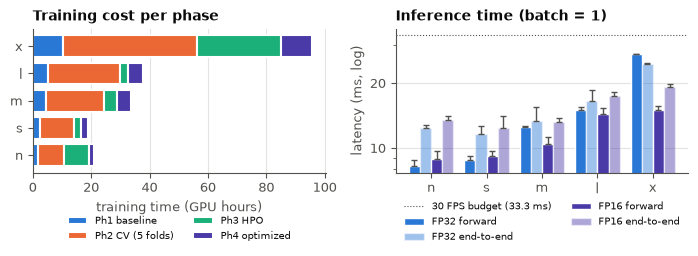

phase,phase1_baseline,phase2_cv_baseline,phase3_hpo,phase4_optimized
model,,,,
nano,1.70,9.09,8.37,1.68
small,2.50,11.55,2.50,2.47
medium,4.52,19.95,4.53,4.50
large,5.28,24.65,2.65,5.27
xlarge,10.50,45.63,28.90,10.47


fwd_median_ms  fwd_p95_ms  fwd_fps  e2e_median_ms  \
model  precision                                                      
nano   fp32                8.26        8.85   119.98          12.45   
       fp16                8.89        9.67   111.09          13.55   
small  fp32                8.78        9.18   112.92          11.60   
       fp16                9.18        9.68   107.95          12.42   
medium fp32               12.54       12.68    79.75          13.30   
       fp16               10.41       11.22    95.05          13.28   
large  fp32               14.94       15.47    66.61          16.61   
       fp16               14.41       15.42    68.56          17.39   
xlarge fp32               27.17       27.41    36.79          24.55   
       fp16               14.97       15.64    66.19          19.11   

                  e2e_p95_ms  e2e_dataset_median_ms  e2e_dataset_p95_ms  \
model  precision                                                          
nano   fp32            12.82                  11.56               12.69   
       fp16            14.06                  12.32               13.59   
small  fp32            12.72                  11.69               12.40   
       fp16            14.11                  12.50               14.29   
medium fp32            15.43                  13.46               14.13   
       fp16            13.85                  13.51               15.67   
large  fp32            18.50                  16.66               18.91   
       fp16            18.27                  17.67               19.20   
xlarge fp32            24.83                  23.25               24.59   
       fp16            19.84                  17.96               19.67   

                  e2e_fps  real-time (30 FPS, e2e_dataset_p95_ms)  
model  precision                                                   
nano   fp32         79.79                                    True  
       fp16         73.33                                    True  
small  fp32         84.97                                    True  
       fp16         79.17                                    True  
medium fp32         72.99                                    True  
       fp16         74.72                                    True  
large  fp32         59.17                                    True  
       fp16         56.84                                    True  
xlarge fp32         40.71                                    True  
       fp16         51.94                                    True

In [11]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    REALTIME_FPS = 30   # frame-rate target of the real-time criterion (budget = 1000 / REALTIME_FPS ms)
    cost = read_csv("training_cost")
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
    if len(cost):
        phases = ["phase1_baseline", "phase2_cv_baseline", "phase3_hpo", "phase4_optimized"]
        labels = {"phase1_baseline": "Ph1 baseline", "phase2_cv_baseline": "Ph2 CV (5 folds)",
                  "phase3_hpo": "Ph3 HPO", "phase4_optimized": "Ph4 optimized"}
        colors = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"]
        left = np.zeros(len(MODELS))
        for ph, col in zip(phases, colors):
            v = cost[cost.phase == ph].set_index("model").reindex(MODELS)["train_hours"].fillna(0).to_numpy()
            axes[0].barh(X, v, left=left, color=col, edgecolor=SURFACE, linewidth=1.5, label=labels[ph])
            left += v
        axes[0].set_yticks(X, [SHORT[m] for m in MODELS])
        axes[0].set_xlabel("training time (GPU hours)")
        axes[0].set_title("Training cost per phase")
        axes[0].grid(True, axis="x"); axes[0].grid(False, axis="y")
        axes[0].legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.24))
    w = 0.2
    for i, (prec, scope) in enumerate([(p, s) for p in ("fp32", "fp16") for s in ("fwd", "e2e")]):
        d = eff[(eff.variant == DEPLOY_VARIANT) & (eff.precision == prec)].set_index("model").reindex(MODELS)
        med, p95 = d[f"{scope}_median_ms"].to_numpy(), d[f"{scope}_p95_ms"].to_numpy()
        xs = X + (i - 1.5) * w
        axes[1].bar(xs, med, width=w, color=PREC[prec], alpha=1.0 if scope == "fwd" else 0.45, edgecolor=SURFACE,
                    linewidth=1, label=f"{prec.upper()} {'forward' if scope == 'fwd' else 'end-to-end'}")
        axes[1].errorbar(xs, med, yerr=np.vstack([np.zeros_like(med), p95 - med]), fmt="none", ecolor=INK_2,
                         elinewidth=1, capsize=2)
    axes[1].axhline(1000 / REALTIME_FPS, color=INK_2, linewidth=0.8, linestyle=":",
                    label=f"{REALTIME_FPS} FPS budget ({1000 / REALTIME_FPS:.1f} ms)")
    axes[1].set_xticks(X, [SHORT[m] for m in MODELS])
    log_axis(axes[1], "y")
    axes[1].set_ylabel("latency (ms, log)")
    axes[1].set_title("Inference time (batch = 1)")
    axes[1].legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.14))
    fig.tight_layout()
    save(fig, "figB_training_inference_time")
    plt.show()
    if len(cost):
        display(cost.pivot(index="model", columns="phase", values="train_hours").reindex(MODELS).round(2))
    rt = eff[eff.variant == DEPLOY_VARIANT].set_index(["model", "precision"]).reindex(MODELS, level=0)
    p95_col = "e2e_dataset_p95_ms" if "e2e_dataset_p95_ms" in rt and rt["e2e_dataset_p95_ms"].notna().all() else "e2e_p95_ms"
    realtime = rt[[c for c in ("fwd_median_ms", "fwd_p95_ms", "fwd_fps", "e2e_median_ms", "e2e_p95_ms",
                               "e2e_dataset_median_ms", "e2e_dataset_p95_ms", "e2e_fps") if c in rt]].copy()
    realtime[f"real-time ({REALTIME_FPS} FPS, {p95_col})"] = rt[p95_col] <= 1000 / REALTIME_FPS
    display(realtime.round(2))

## Standard figure C — Boundary metrics on the test set (Metrics Reloaded)

Boundary IoU (band = 2 % of the image diagonal), Normalised Surface Distance (tolerance = 1 % of the diagonal) and
HD95 (95th-percentile symmetric Hausdorff distance in pixels at dataset resolution; lower is better; a missed lesion
scores the image diagonal), per-image mean with seeded bootstrap 95 % CI, Baseline vs. Optimized (FP32). Overlap
scores (DSC, JSI) are dominated by the lesion interior; these scores measure contour adherence. The paired
Optimized − Baseline differences (bootstrap CI, Wilcoxon *p*) are in `summary/hpo_gain.csv`.

saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/figures/figC_boundary_metrics.pdf|png


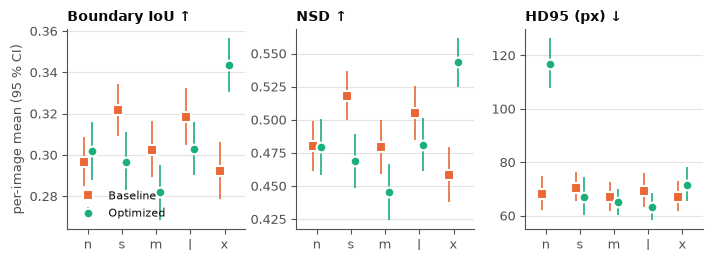

biou_mean  biou_std  biou_median  biou_ci95_low  \
model  variant                                                      
nano   baseline      0.2966    0.2005       0.2675         0.2849   
       optimized     0.3019    0.2341       0.2682         0.2878   
small  baseline      0.3219    0.2024       0.3039         0.3094   
       optimized     0.2966    0.2199       0.2631         0.2832   
medium baseline      0.3024    0.2181       0.2741         0.2894   
       optimized     0.2821    0.2191       0.2442         0.2684   
large  baseline      0.3183    0.2244       0.2938         0.3048   
       optimized     0.3028    0.2119       0.2725         0.2901   
xlarge baseline      0.2921    0.2274       0.2600         0.2786   
       optimized     0.3436    0.2149       0.3281         0.3307   

                  biou_ci95_high  nsd_mean  nsd_std  nsd_median  nsd_ci95_low  \
model  variant                                                                  
nano   baseline           0.3089    0.4800   0.3082      0.4742        0.4616   
       optimized          0.3160    0.4795   0.3456      0.4667        0.4582   
small  baseline           0.3344    0.5183   0.3004      0.5249        0.4996   
       optimized          0.3110    0.4685   0.3310      0.4456        0.4482   
medium baseline           0.3163    0.4794   0.3281      0.4558        0.4594   
       optimized          0.2954    0.4455   0.3340      0.4262        0.4242   
large  baseline           0.3322    0.5051   0.3359      0.5088        0.4847   
       optimized          0.3161    0.4812   0.3201      0.4745        0.4614   
xlarge baseline           0.3064    0.4581   0.3398      0.4378        0.4379   
       optimized          0.3564    0.5434   0.3063      0.5525        0.5250   

                  nsd_ci95_high  hd95_mean  hd95_std  hd95_median  \
model  variant                                                      
nano   baseline          0.4988    68.0345  102.5901      33.0000   
       optimized         0.5006   116.8343  150.8430      40.7308   
small  baseline          0.5367    70.4931   91.9776      35.9597   
       optimized         0.4895    67.1041  111.6011      32.1184   
medium baseline          0.4999    67.0917   90.7427      35.0243   
       optimized         0.4664    65.0077   83.1536      34.9814   
large  baseline          0.5255    69.2667  104.0898      32.5788   
       optimized         0.5012    63.1401   84.5525      32.0167   
xlarge baseline          0.4795    67.1664   89.8109      36.7332   
       optimized         0.5614    71.5140  104.3119      32.0000   

                  hd95_ci95_low  hd95_ci95_high  
model  variant                                   
nano   baseline         62.0940         74.7627  
       optimized       107.9259        126.3487  
small  baseline         65.3425         76.3054  
       optimized        60.4065         74.6456  
medium baseline         61.9376         72.5637  
       optimized        60.0972         70.1635  
large  baseline         63.2170         75.8196  
       optimized        58.3266         68.4291  
xlarge baseline         61.7799         72.8632  
       optimized        65.6139         78.1899

In [12]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    keys_c = [(k, t) for k, t in (("biou", "Boundary IoU ↑"), ("nsd", "NSD ↑"), ("hd95", "HD95 (px) ↓")) if f"{k}_mean" in acc32 and acc32[f"{k}_mean"].notna().any()]
    if not keys_c:
        print("Boundary metrics not in test_accuracy.csv — re-run Phase 5a (evaluate_test_set.py, EVAL_VERSION >= 3).")
    else:
        fig, axes = plt.subplots(1, len(keys_c), figsize=(7.2, 2.7), squeeze=False)
        for ax, (k, title) in zip(axes[0], keys_c):
            for off, v in ((-0.12, "baseline"), (0.12, "optimized")):
                d = acc32[acc32.variant == v].set_index("model").reindex(MODELS)
                m_ = d[f"{k}_mean"].to_numpy()
                err = np.vstack([m_ - d[f"{k}_ci95_low"].to_numpy(), d[f"{k}_ci95_high"].to_numpy() - m_])
                ax.errorbar(X + off, m_, yerr=err, fmt=MARKER[v], color=SERIES[v], elinewidth=1.2, capsize=0,
                            markeredgecolor=SURFACE, markeredgewidth=1.5, markersize=7, label=v.capitalize())
            ax.set_xticks(X, [SHORT[m] for m in MODELS])
            ax.set_xlim(-0.6, len(MODELS) - 0.4)
            ax.set_title(title)
        axes[0, 0].set_ylabel("per-image mean (95 % CI)")
        axes[0, 0].legend(loc="lower left")
        fig.tight_layout()
        save(fig, "figC_boundary_metrics")
        plt.show()
        display(acc32.set_index(["model", "variant"])[[c for c in acc32.columns if c.startswith(("biou_", "nsd_", "hd95_"))]]
                .reindex(MODELS, level=0).round(4))

## LaTeX tables
`booktabs` tables for the thesis, written to `<pipeline>/tables/`.

In [13]:
if not PHASE5_READY:
    print(PHASE5_MISSING)
else:
    def to_latex(df: pd.DataFrame, name: str, caption: str) -> None:
        try:
            tex = df.to_latex(float_format="%.4f", caption=caption, label=f"tab:{name}", escape=True)
        except ImportError as err:  # pandas' LaTeX writer needs jinja2 (bundled with jupyterlab)
            print(f"[skip] {name}: {err}")
            return
        TABLE_DIR.mkdir(parents=True, exist_ok=True)
        (TABLE_DIR / f"{name}.tex").write_text(tex)
        print(f"saved {TABLE_DIR / name}.tex")


    if len(acc32):
        t = acc32.pivot(index="model", columns="variant",
                        values=[k for k in ("dsc_mean", "jsi_mean", "jsi_thr_mean", "biou_mean", "nsd_mean", "hd95_mean", "map5095_m") if k in acc32]).reindex(MODELS)
        t.columns = [f"{v} {k.replace('_mean', '').upper()}" for k, v in t.columns]
        to_latex(t, "test_accuracy", "Test-set accuracy of the Baseline and Optimized YOLO26-seg models (FP32).")
    if len(e):
        t = e.set_index(["model", "precision"])[
            [c for c in ("params_fused", "gflops", "input_px", "size_mb_disk", "fwd_median_ms", "fwd_p95_ms", "fwd_fps",
                         "e2e_median_ms", "e2e_p95_ms", "e2e_dataset_p95_ms", "vram_peak_allocated_mb",
                         "vram_process_peak_mb") if c in e]
        ].reindex(MODELS, level=0)
        to_latex(t, "efficiency", "Batch-1 efficiency of the deployed YOLO26-seg models (FP32 vs. FP16).")

saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/tables/test_accuracy.tex
saved /home/antoniovinicius/projects/sandbox_yolo26/logs/pipeline_final_v1/tables/efficiency.tex


## Reading notes

* **Contended runs.** `contended = True` means another process used the GPU during the benchmark;
  re-run Phase 5b on an idle GPU before quoting those latencies.
* **Model size.** Ultralytics stores final checkpoints in FP16, so `size_mb_disk` ≈ the FP16 size; the
  theoretical FP32/FP16 sizes are fused parameters × 4 / × 2 bytes.
* **VRAM.** `vram_peak_allocated_*` are PyTorch-allocator figures at steady state (the CUDA context, a few
  hundred MB, excluded); `vram_process_peak_mb` is the driver-level footprint of the benchmark process
  (context and allocator cache included) — quote it for "fits on device X" claims.
* **Latency scopes.** `fwd_*` = network only (CUDA events); `e2e_*` = full pipeline on one test image
  repeated; `e2e_dataset_*` = full pipeline once on each of 100 distinct test images (input-dependent
  spread). The per-image `infer_ms` column of `phase5_test/per_image/*.csv` is a by-product of Phase 5a,
  not a benchmark — never quote it.
* **CV vs. test.** CV uses the Baseline protocol on held-out folds of train+val; only Phase 5 touches the test set.